# Dire al modello in che ordine stanno le parole, senza dirgli dove sono

*Anatomia di un LLM* · capitolo 4, «Dal testo ai numeri» · nel libro: §4.4 «In che ordine stanno» · script `02-06`, `scripts/02_06_rope.py`

**Dove siamo.** L'attenzione confronta coppie di parole senza guardare dove si trovano. RoPE rimedia ruotando i vettori di un angolo che dipende dalla posizione, e qui si controlla la sua proprietà: conta solo la distanza.

L'attenzione da sola non sa nulla dell'ordine: mescolando le parole otterrebbe
lo stesso risultato. RoPE risolve ruotando i vettori di un angolo che dipende
dalla posizione, con una conseguenza sorprendente: il punteggio fra due parole
finisce per dipendere solo da quanto sono lontane, non da dove si trovano.

Si esegue con `python3 scripts/02_06_rope.py` e dura circa 5 secondi.

> **Per riottenere i numeri del libro** esegui le celle in ordine, dalla prima. Il seme si fissa una volta sola, in `prepara()`: rieseguire una cella a metà cambia i numeri casuali di tutte quelle dopo.

[Apri in Colab](https://colab.research.google.com/github/fcollova/llm-anatomy/blob/main/notebooks/02_06_rope.ipynb) · la prima cella scarica il codice, se non lo trova accanto.

In [ ]:
# Porta il notebook nella cartella che contiene llm_anatomy/, da dovunque
# sia stato aperto: gli script si eseguono da li', e cosi' anche le celle.
import os
import subprocess
import sys
from pathlib import Path

radice = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "llm_anatomy").is_dir()), None)

if radice is None:
    # Il notebook e' stato aperto da solo, per esempio su Colab: il codice, il
    # testo e il modello addestrato si scaricano una volta, qui accanto.
    REPO, RAMO, CARTELLA = "fcollova/llm-anatomy", "main", ""
    copia = Path("anatomia-di-un-llm")
    if not copia.exists():
        esito = subprocess.run(
            ["git", "clone", "-q", "--depth", "1", "--branch", RAMO,
             f"https://github.com/{REPO}.git", str(copia)], capture_output=True)
        if esito.returncode != 0:
            raise SystemExit("Non riesco a scaricare il codice da github.com/"
                             + REPO + ": " + esito.stderr.decode()[-300:])
    radice = copia / CARTELLA

os.chdir(radice)
sys.path.insert(0, str(Path.cwd()))

In [ ]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch

from llm_anatomy.model import applica_rope, frequenze_rope
from llm_anatomy.utils import (dec, figura, prepara, stampa_shape, stile_figure,
                               tabella, titolo, verifica)

prepara()

d_head, T = 32, 256
cos, sin = frequenze_rope(d_head, T)
stampa_shape("cos", cos)
stampa_shape("sin", sin)
print(f"  ogni coppia di canali ruota di un angolo proporzionale alla "
      f"posizione")

[ambiente] torch 2.13.0+cpu  device=cpu  threads=8  seed=1337
  cos                          (256, 16)              float32
  sin                          (256, 16)              float32
  ogni coppia di canali ruota di un angolo proporzionale alla posizione


### Due parole, spostate insieme lungo la frase

> **Nel libro, §4.4 «In che ordine stanno».** Come sa il modello in che ordine stanno le parole, se l'attenzione non lo guarda?

**Cosa guardare.** L'ultima colonna resta 7,9298 spostando la coppia lungo la frase: cambia la posizione, non la distanza.

In [ ]:
titolo("Due parole, spostate insieme lungo la frase")
q = torch.randn(1, 1, 1, d_head)
k = torch.randn(1, 1, 1, d_head)
print(f"  prodotto scalare senza rotazione: {(q * k).sum().item():.6f}")
print()

distanza = 5
righe = []
for m in (0, 10, 50, 100, 200):
    n = m + distanza
    qm = applica_rope(q, cos[m:m + 1], sin[m:m + 1])
    kn = applica_rope(k, cos[n:n + 1], sin[n:n + 1])
    righe.append([m, n, n - m, dec((qm * kn).sum().item(), 6)])
tabella(["pos. query", "pos. chiave", "differenza", "prodotto scalare"], righe)

valori = []
for m in range(0, T - distanza):
    qm = applica_rope(q, cos[m:m + 1], sin[m:m + 1])
    kn = applica_rope(k, cos[m + distanza:m + distanza + 1],
                      sin[m + distanza:m + distanza + 1])
    valori.append((qm * kn).sum().item())
scarto = max(valori) - min(valori)
print(f"  su tutte le {len(valori)} posizioni possibili "
      f"a distanza {distanza},")
print(f"  lo scarto fra massimo e minimo e' {scarto:.3e}")
verifica(scarto < 1e-4,
         "il punteggio dipende solo da m-n, non dalle posizioni assolute")


Due parole, spostate insieme lungo la frase
-------------------------------------------
  prodotto scalare senza rotazione: 8.116568

pos. query  pos. chiave  differenza  prodotto scalare
----------  -----------  ----------  ----------------
0                     5           5          7,929830
10                   15           5          7,929831
50                   55           5          7,929832
100                 105           5          7,929832
200                 205           5          7,929834
  su tutte le 251 posizioni possibili a distanza 5,
  lo scarto fra massimo e minimo e' 1.574e-05
  [verifica superata] il punteggio dipende solo da m-n, non dalle posizioni
                      assolute


### Conta solo quanto sono lontane

**Cosa guardare.** Quando la distanza cambia, il punteggio cambia: è l'informazione che la rotazione porta dentro l'attenzione.

**Prova a cambiare:** aggiungi le distanze `200` e `250`.

<details><summary>Che cosa succede</summary>

A 200 il punteggio sale a 15,09, a 250 scende a 8,95: con la distanza non decresce in modo regolare, oscilla.

</details>

In [ ]:
titolo("Conta solo quanto sono lontane")
righe = []
for dist in (0, 1, 2, 8, 32, 128):
    q0 = applica_rope(q, cos[0:1], sin[0:1])
    kd = applica_rope(k, cos[dist:dist + 1], sin[dist:dist + 1])
    righe.append([dist, dec((q0 * kd).sum().item(), 4)])
tabella(["distanza", "prodotto scalare"], righe)
print("  a distanza zero il punteggio e' quello dei vettori non ruotati:")
print("  RoPE non aggiunge informazione, la ridistribuisce fra gli angoli")


Conta solo quanto sono lontane
------------------------------
distanza  prodotto scalare
--------  ----------------
0                   8,1166
1                   7,5351
2                   7,2585
8                   9,5728
32                 10,0548
128                10,4057
  a distanza zero il punteggio e' quello dei vettori non ruotati:
  RoPE non aggiunge informazione, la ridistribuisce fra gli angoli


### Il metodo del 2017 non si comporta così

*Questa parte non è stampata nel libro.*

**Cosa guardare.** La differenza pratica: la posizione sommata occupa spazio nel vettore, la rotazione no.

In [ ]:
titolo("Il metodo del 2017 non si comporta cosi'")
print("  i posizionali sinusoidali si sommano all'embedding e occupano quindi")
print("  parte del residual stream. RoPE ruota solo query e chiave dentro")
print("  l'attenzione: l'embedding resta intatto, e la posizione non consuma")
print("  capacita' del flusso residuo")


Il metodo del 2017 non si comporta cosi'
----------------------------------------
  i posizionali sinusoidali si sommano all'embedding e occupano quindi
  parte del residual stream. RoPE ruota solo query e chiave dentro
  l'attenzione: l'embedding resta intatto, e la posizione non consuma
  capacita' del flusso residuo


### Ruotare non allunga niente

*Questa parte non è stampata nel libro.*

**Cosa guardare.** La verifica: la lunghezza dei vettori non cambia ruotandoli.


Ruotare non allunga niente
--------------------------
  [verifica superata] la rotazione conserva la norma dei vettori


  [figura] outputs/figures/02-06_rope.pdf


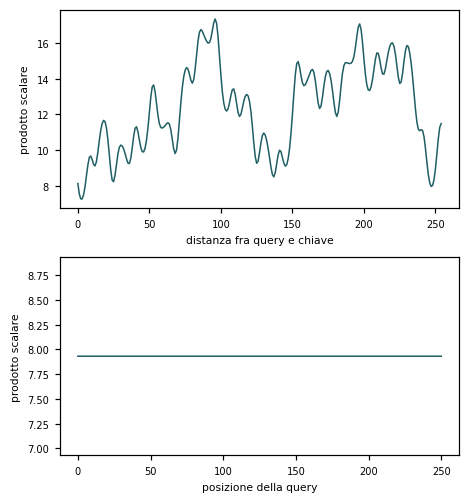

In [ ]:
titolo("Ruotare non allunga niente")
qm = applica_rope(q, cos[42:43], sin[42:43])
verifica(abs(qm.norm().item() - q.norm().item()) < 1e-5,
         "la rotazione conserva la norma dei vettori")

profili = {}
for dist_max in (T - 1,):
    q0 = applica_rope(q, cos[0:1], sin[0:1])
    serie = []
    for dist in range(dist_max):
        kd = applica_rope(k, cos[dist:dist + 1], sin[dist:dist + 1])
        serie.append((q0 * kd).sum().item())
    profili["punteggio"] = serie

fig, ax = plt.subplots(2, 1, figsize=(stile_figure(), 4.6))
ax[0].plot(profili["punteggio"], lw=1)
ax[0].set_xlabel("distanza fra query e chiave")
ax[0].set_ylabel("prodotto scalare")
ax[1].plot(valori, lw=1)
ax[1].set_xlabel("posizione della query")
ax[1].set_ylabel("prodotto scalare")
ax[1].set_ylim(min(valori) - 1, max(valori) + 1)
fig.tight_layout()
figura(fig, "02-06_rope")